# 04 Machine learning จำแนกน้ำท่วมจากภาพ SAR: Random Forest เทียบ XGBoost

**ชุดการสอน:** Teach_SAR_flood_Mapping_ML | **เวลาโดยประมาณ:** 120 นาที | **ต้องทำก่อน:** `02`

## จุดประสงค์
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. สร้างตาราง feature จากภาพ SAR หลายแบนด์ และอธิบายที่มาของ label
2. อธิบายว่าทำไมต้องแบ่ง train/test **เชิงพื้นที่** และแบ่งได้ด้วยตนเอง
3. ฝึกโมเดล Random Forest และ XGBoost และปรับ hyperparameter เบื้องต้น
4. อ่าน feature importance และรู้ข้อจำกัดของมัน

แนวทางดัดแปลงจาก Al Mehedi et al. (SAR-Urban-Flood-GEE-ML) ซึ่งใช้ feature ชุด VV, VH สองช่วงเวลา และเทียบ Random Forest กับ XGBoost

## ข้อตกลงสำคัญ: label ของเรามาจากไหน

Machine learning แบบมีผู้สอนต้องการ **ข้อมูลอ้างอิง (ground truth)** ว่าจุดใดท่วมจริง ในงานวิจัยได้มาจาก
- การสำรวจภาคสนามด้วย GPS ระหว่างหรือหลังเหตุการณ์
- การแปลภาพถ่ายความละเอียดสูงด้วยสายตา
- แผนที่น้ำท่วมจากหน่วยงาน เช่น GISTDA

รายวิชานี้ไม่มีข้อมูลดังกล่าว จึง **จำลอง** โดยใช้แผนที่ threshold จาก `02` เป็น label เรียกว่า **pseudo-label** ผลที่ตามมาคือ

> ตัวเลขความถูกต้องทุกตัวใน `04` และ `05` หมายถึง **ความสอดคล้องกับแผนที่ threshold** ไม่ใช่ความถูกต้องเทียบกับน้ำท่วมจริง ถ้า threshold ผิด โมเดลก็จะเรียนสิ่งที่ผิดตามไปด้วย

เพื่อไม่ให้โมเดลแค่ลอกสูตร threshold เราทำสองอย่าง คือ (1) เลือกเฉพาะจุดภาพที่ **มั่นใจ** ว่าท่วมหรือไม่ท่วม และทิ้งจุดกำกวมใกล้ค่า threshold (2) label สร้างจาก VH ที่ **กรองแล้ว** แต่โมเดลเรียนจากแบนด์ **ดิบ** ทั้ง VV และ VH

## 0. เตรียมสภาพแวดล้อม
เซลล์นี้ดาวน์โหลดข้อมูลและฟังก์ชันกลาง (`sarflood_utils.py`) จาก GitHub ของรายวิชา **notebook นี้ไม่ต้องใช้ Google Earth Engine** เพราะข้อมูลถูกเตรียมไว้แล้วใน `00`

รูปทุกรูปใช้ป้ายกำกับภาษาอังกฤษ เพราะเป็นมาตรฐานของวารสารนานาชาติ และ Colab ไม่มีฟอนต์ไทยสำหรับ matplotlib

In [1]:
!pip -q install rasterio

import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = 'Teach_SAR_flood_Mapping_ML'
if not os.path.isdir(REPO):
    !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git
sys.path.insert(0, REPO)
import sarflood_utils as su

DATA = f'{REPO}/data'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
print('ไฟล์ข้อมูล:', sorted(os.listdir(DATA)))

ไฟล์ข้อมูล: ['S1_20171017_VH.tif', 'S1_20171017_VV.tif', 'S1_20180109_VH.tif', 'S1_20180109_VV.tif', 'boundary_amphoe.geojson', 'boundary_province.geojson', 'dem_srtm.tif', 'ghsl_pop_2020.tif', 'jrc_seasonality.tif', 'readme.txt', 'slope_srtm.tif', 'worldcover_2020.tif']


## 1. สร้าง feature

| Feature | ความหมาย | เหตุผล |
|---|---|---|
| `VV_flood`, `VH_flood` | backscatter วันน้ำท่วม (dB) | น้ำเปิดมีค่าต่ำ |
| `VV_ref`, `VH_ref` | backscatter วันอ้างอิง (dB) | บอกสภาพปกติของพื้นผิว |
| `CR_flood`, `CR_ref` | VH − VV (dB) หรือ cross-polarization ratio | แยกพืชพรรณออกจากผิวเรียบ |
| `elevation`, `slope` | ความสูงและความลาดชัน | น้ำขังในที่ต่ำและราบ (ใช้ในแบบฝึกหัด) |

In [2]:
fm = su.flood_change_map(DATA, threshold=su.DIFF_THRESHOLD)      # แผนที่ threshold จาก 02
feats, grid = su.make_features(DATA)
amphoe, province = su.load_boundaries(DATA, grid['crs'])

FEATURES = su.FEATURE_SETS['sar_with_ratio']
print('feature ที่ใช้:', FEATURES)

feature ที่ใช้: ['VV_flood', 'VH_flood', 'VV_ref', 'VH_ref', 'CR_flood', 'CR_ref']


## 2. สุ่มจุดตัวอย่างพร้อม pseudo-label

ให้ $T$ เป็น threshold และ $m$ = 1.5 dB เป็นระยะกันชน
- **ท่วม (1):** อยู่ในแผนที่น้ำท่วม และ $\Delta\sigma^0 < T - m$
- **ไม่ท่วม (0):** $\Delta\sigma^0 > T + m$ และไม่ใช่น้ำถาวร
- **กำกวม:** ค่าอยู่ระหว่าง $T \pm m$ ไม่นำมาใช้

สุ่มคลาสละเท่ากัน (balanced) และเก็บพิกัดกับรหัสบล็อกขนาด 5 กม. ของทุกจุดไว้ด้วย

In [3]:
df = su.sample_pseudo_labels(fm, feats, n_per_class=10000, margin=1.5, block_km=5.0, seed=42)
print('จำนวนตัวอย่างต่อคลาส:', df['label'].value_counts().to_dict(), '| จำนวนบล็อก:', df['block'].nunique())
df.head()

จำนวนตัวอย่างต่อคลาส: {0: 10000, 1: 10000} | จำนวนบล็อก: 108


,row,col,x,y,block,label,VV_flood,VH_flood,VV_ref,VH_ref,CR_flood,CR_ref,elevation,slope
0,4577,103,591045.0,1842755.0,9000,0,0.00,0.00,0.00,0.00,0.00,0.00,0.000000,0.000000e+00
1,3130,1771,607725.0,1857225.0,6003,1,-21.64,-26.00,-7.93,-25.09,-4.36,-17.16,43.000000,6.616574e-13
2,2376,1159,601605.0,1864765.0,4002,1,-20.86,-25.57,-9.26,-17.29,-4.71,-8.03,42.666668,1.343333e+00
3,2400,897,598985.0,1864525.0,4001,1,-15.78,-20.59,-13.35,-17.53,-4.81,-4.18,43.000000,2.138889e+00
4,4610,3165,621665.0,1842425.0,9006,0,-11.20,-14.53,-9.35,-15.62,-3.33,-6.27,41.111111,3.254445e+00


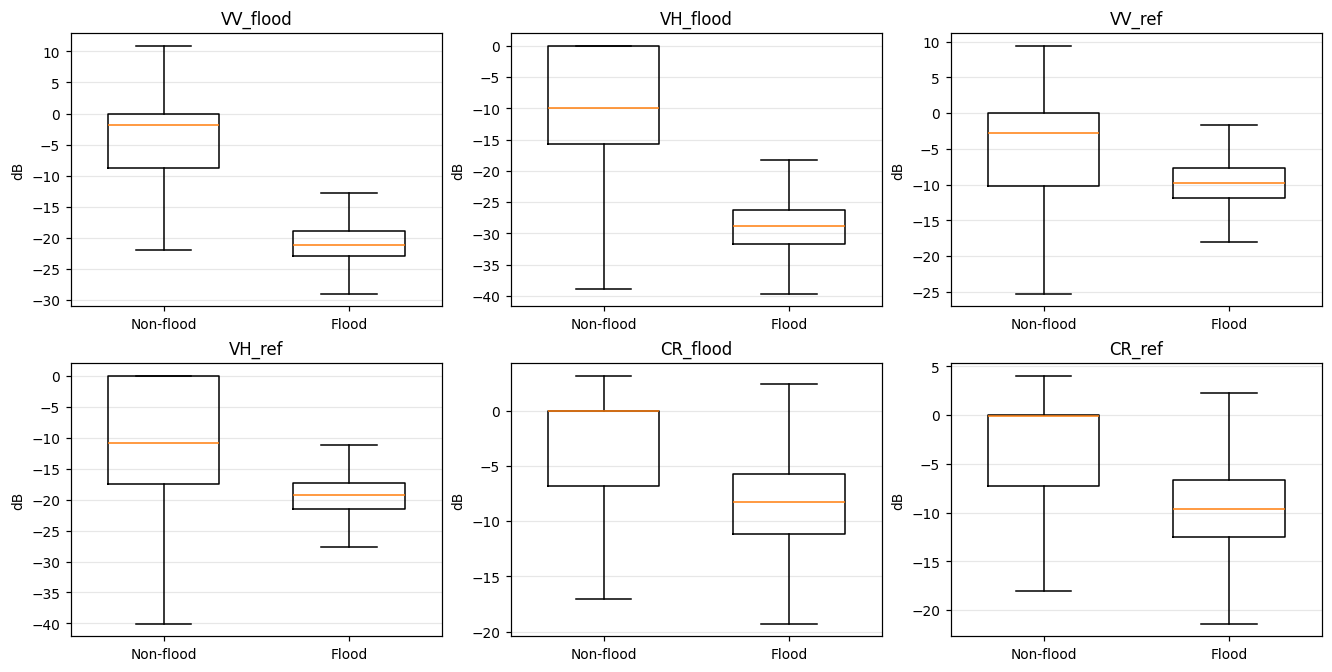

In [4]:
# การกระจายของแต่ละ feature แยกตามคลาส
fig, axes = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
for ax, f in zip(axes.ravel(), FEATURES):
    ax.boxplot([df.loc[df['label'] == k, f] for k in [0, 1]], showfliers=False, widths=0.6)
    ax.set_xticks([1, 2]); ax.set_xticklabels(['Non-flood', 'Flood'])
    ax.set_title(f); ax.set_ylabel('dB'); ax.grid(axis='y', alpha=0.3)
plt.show()

## 3. แบ่ง train/test เชิงพื้นที่

จุดภาพที่อยู่ใกล้กันมีค่าคล้ายกัน (spatial autocorrelation) ถ้าสุ่มแบ่งแบบธรรมดา จุดทดสอบจะมีเพื่อนบ้านอยู่ในชุดฝึกเกือบทุกจุด โมเดลจึงเหมือนได้เห็นข้อสอบล่วงหน้า และความถูกต้องจะสูงเกินจริง

ทางแก้คือแบ่งเป็น **บล็อก** แล้วให้ทุกจุดในบล็อกเดียวกันอยู่ฝั่งเดียวกัน ชุดทดสอบจึงเป็นพื้นที่ที่โมเดลไม่เคยเห็น

train: 14,625 จุด ใน 75 บล็อก | test: 5,375 จุด ใน 33 บล็อก


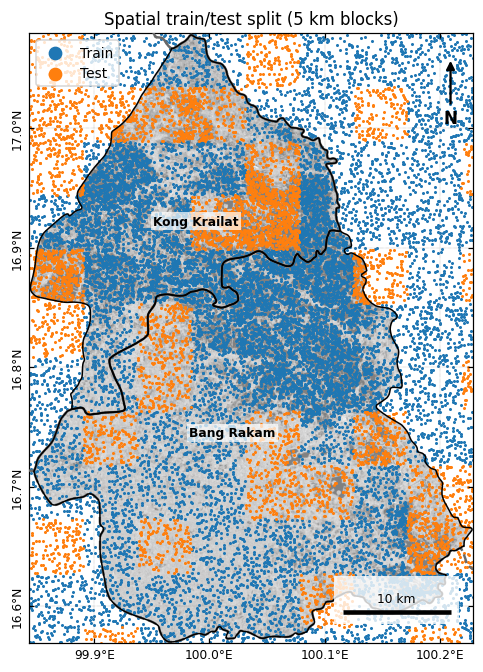

In [5]:
train, test = su.spatial_split(df, test_size=0.3, seed=42)
print(f'train: {len(train):,} จุด ใน {train["block"].nunique()} บล็อก | '
      f'test: {len(test):,} จุด ใน {test["block"].nunique()} บล็อก')

fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
ax.imshow(fm['flood_img'], cmap='gray', vmin=-27, vmax=-7, alpha=0.5, extent=su.extent(grid))
ax.scatter(train['x'], train['y'], s=1, color='tab:blue', label='Train')
ax.scatter(test['x'], test['y'], s=1, color='tab:orange', label='Test')
su.journal_map(ax, grid, amphoe, province)
ax.legend(markerscale=8, loc='upper left'); ax.set_title('Spatial train/test split (5 km blocks)')
plt.show()

X_train, y_train = train[FEATURES], train['label']
X_test, y_test = test[FEATURES], test['label']

## 4. Random Forest

Random Forest สร้างต้นไม้ตัดสินใจจำนวนมาก แต่ละต้นเรียนจากตัวอย่างที่สุ่มแบบใส่คืน (bootstrap) และสุ่มเลือก feature ที่แต่ละจุดแยก แล้วให้ทุกต้นลงคะแนน (**bagging**) จุดแยกแต่ละจุดเลือกจากค่า Gini impurity ที่ลดลงมากที่สุด

$$G = 1 - \sum_{k} p_k^2$$

โดย $p_k$ คือสัดส่วนของคลาส $k$ ในโหนด $G = 0$ เมื่อโหนดมีคลาสเดียว และ $G = 0.5$ เมื่อสองคลาสมีเท่ากัน

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
print(f'Random Forest  accuracy = {accuracy_score(y_test, pred_rf):.3f}  F1 = {f1_score(y_test, pred_rf):.3f}')

Random Forest  accuracy = 0.972  F1 = 0.966


## 5. XGBoost

XGBoost ใช้ **boosting** คือสร้างต้นไม้ทีละต้นต่อเนื่องกัน ต้นใหม่เรียนเพื่อแก้ความผิดพลาดของต้นก่อนหน้า

$$F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$$

โดย $h_m$ คือต้นไม้ต้นที่ $m$ และ $\eta$ คือ learning rate ค่า $\eta$ เล็กทำให้เรียนช้าแต่มั่นคง จึงต้องใช้จำนวนต้นมากขึ้น

| | Random Forest | XGBoost |
|---|---|---|
| วิธีรวมต้นไม้ | ขนานกัน แล้วลงคะแนน | ต่อเนื่องกัน แก้ความผิดพลาดทีละขั้น |
| ลดความคลาดเคลื่อนแบบ | variance | bias |
| ความไวต่อ hyperparameter | น้อย | มากกว่า |

In [7]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.8,
                    tree_method='hist', n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)
print(f'XGBoost        accuracy = {accuracy_score(y_test, pred_xgb):.3f}  F1 = {f1_score(y_test, pred_xgb):.3f}')

XGBoost        accuracy = 0.968  F1 = 0.961


## 6. ปรับ hyperparameter ด้วย random search

สุ่มลองชุดค่าจำนวนหนึ่ง แล้ววัดผลด้วย cross-validation **เชิงพื้นที่** (`GroupKFold`) บนชุดฝึกเท่านั้น ชุดทดสอบต้องไม่ถูกแตะจนกว่าจะประเมินขั้นสุดท้าย เพื่อประหยัดเวลาเราลองเพียง 8 ชุด งานจริงมักลอง 50 ชุดขึ้นไป

In [8]:
from sklearn.model_selection import RandomizedSearchCV, GroupKFold

param_dist = {'n_estimators': [50, 100, 200], 'max_depth': [6, 10, 16, None],
              'min_samples_leaf': [1, 5, 20], 'max_features': ['sqrt', 0.5, 1.0]}
search = RandomizedSearchCV(RandomForestClassifier(n_jobs=-1, random_state=42), param_dist,
                            n_iter=8, cv=GroupKFold(n_splits=3), scoring='f1', random_state=42)
search.fit(X_train, y_train, groups=train['block'])

print('ชุดค่าที่ดีที่สุด:', search.best_params_)
print(f'F1 เฉลี่ยจาก cross-validation = {search.best_score_:.3f}')
print(f'F1 บนชุดทดสอบ = {f1_score(y_test, search.best_estimator_.predict(X_test)):.3f}')

ชุดค่าที่ดีที่สุด: {'n_estimators': 50, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}
F1 เฉลี่ยจาก cross-validation = 0.974
F1 บนชุดทดสอบ = 0.964


## 7. Feature importance

Random Forest ให้ค่า importance จากผลรวมของ Gini ที่ลดลงเมื่อใช้ feature นั้นแยกโหนด ส่วน **permutation importance** วัดว่าความถูกต้องบนชุดทดสอบลดลงเท่าไรเมื่อสลับค่าของ feature นั้นแบบสุ่ม ซึ่งน่าเชื่อถือกว่าเมื่อ feature มีความสัมพันธ์กันเอง

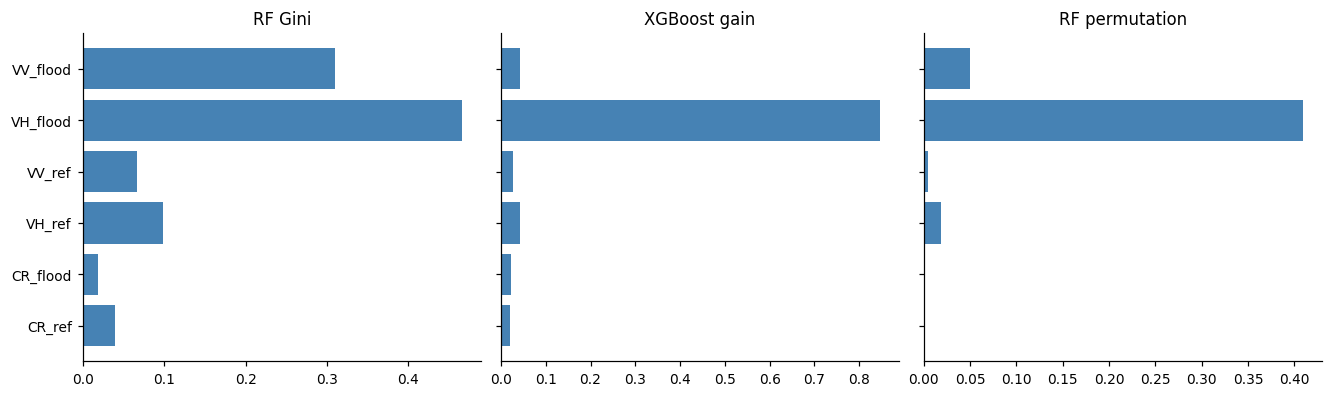

,RF Gini,XGBoost gain,RF permutation
feature,,,
VV_flood,0.310,0.042,0.050
VH_flood,0.466,0.847,0.409
VV_ref,0.067,0.026,0.005
VH_ref,0.099,0.044,0.018
CR_flood,0.018,0.022,0.001
CR_ref,0.040,0.020,0.002


In [9]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.DataFrame({'feature': FEATURES, 'RF Gini': rf.feature_importances_,
                    'XGBoost gain': xgb.feature_importances_,
                    'RF permutation': perm.importances_mean}).set_index('feature')

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True, sharey=True)
for ax, col in zip(axes, imp.columns):
    ax.barh(imp.index, imp[col], color='steelblue'); ax.set_title(col); ax.invert_yaxis()
    ax.spines[['top', 'right']].set_visible(False)
plt.show()
imp.round(3)

In [10]:
# บันทึกตารางตัวอย่าง (มีพิกัดและรหัสบล็อก) เพื่อให้ทำซ้ำได้
os.makedirs('outputs', exist_ok=True)
df.assign(split=np.where(df.index.isin(train.index), 'train', 'test')).to_csv(
    'outputs/samples_pseudo_label.csv', index=False)
print('บันทึก: outputs/samples_pseudo_label.csv')

บันทึก: outputs/samples_pseudo_label.csv


## 8. แบบฝึกหัด

### ข้อ 1 สุ่มแบ่งธรรมดาเทียบกับแบ่งเชิงพื้นที่
ฝึก Random Forest ใหม่โดยแบ่งข้อมูลด้วย `train_test_split` แบบสุ่ม F1 ต่างจากการแบ่งเชิงพื้นที่เท่าไร ค่าใดควรนำไปรายงาน

<details><summary><b>เฉลย</b></summary>

```python
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(df[FEATURES], df['label'], test_size=0.3, random_state=42)
m = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42).fit(Xa, ya)
print('random split F1 :', round(f1_score(yb, m.predict(Xb)), 3))
print('spatial split F1:', round(f1_score(y_test, pred_rf), 3))
```
โดยทั่วไปการสุ่มแบ่งให้ค่าสูงกว่าหรือเท่ากัน ควรรายงานค่าจากการแบ่งเชิงพื้นที่ เพราะสะท้อนการนำโมเดลไปใช้กับพื้นที่ใหม่ ในกรณีนี้ feature เป็นค่าของจุดภาพเดี่ยวและ label มาจากกฎเดียวกันทั้งพื้นที่ ผลต่างจึงอาจเล็ก ผลต่างจะใหญ่ขึ้นมากเมื่อใช้ feature เชิงบริบท เช่น ความสูง หรือ texture
</details>

### ข้อ 2 ตัดและเพิ่ม feature
เปรียบเทียบ F1 ของชุด feature ทั้งสามใน `su.FEATURE_SETS` การเพิ่มความสูงและความลาดชันช่วยหรือไม่ และมีความเสี่ยงอะไร

<details><summary><b>เฉลย</b></summary>

```python
for name, cols in su.FEATURE_SETS.items():
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
    m.fit(train[cols], y_train)
    print(f'{name:20s} F1 = {f1_score(y_test, m.predict(test[cols])):.3f}')
```
ความสูงอาจช่วยเพราะน้ำขังในที่ต่ำ แต่โมเดลอาจจำว่า "ระดับความสูงเท่านี้คือท่วม" ซึ่งเป็นจริงเฉพาะเหตุการณ์และพื้นที่นี้ เมื่อนำไปใช้กับเหตุการณ์อื่นหรือลุ่มน้ำอื่นจะผิดพลาด การแบ่งเชิงพื้นที่ช่วยเผยปัญหานี้ได้บางส่วน
</details>

### ข้อ 3 ระยะกันชนของ pseudo-label
สร้างตัวอย่างใหม่ด้วย `margin=0` แล้วฝึก Random Forest ความถูกต้องเปลี่ยนไปอย่างไร เพราะอะไร

<details><summary><b>เฉลย</b></summary>

```python
df0 = su.sample_pseudo_labels(fm, feats, n_per_class=10000, margin=0.0, seed=42)
tr0, te0 = su.spatial_split(df0)
m = RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=42)
m.fit(tr0[FEATURES], tr0['label'])
print('margin = 0 F1:', round(f1_score(te0['label'], m.predict(te0[FEATURES])), 3))
```
ความถูกต้องมักลดลง เพราะจุดภาพใกล้ค่า threshold มี label ที่ตัดสินจากผลต่างเพียงเล็กน้อยของภาพที่กรองแล้ว ซึ่งโมเดลที่เห็นเฉพาะแบนด์ดิบแยกไม่ออก ข้อสังเกตคือการใช้ `margin` ทำให้ตัวเลขดูดีขึ้นเพราะเราตัดกรณียากออก ต้องระบุเรื่องนี้ในรายงานเสมอ
</details>

### ข้อ 4 คิดต่อ
ถ้านิสิตมีงบประมาณเก็บจุดสำรวจภาคสนามได้ 200 จุด ควรวางแผนสุ่มจุดอย่างไร

<details><summary><b>เฉลย</b></summary>

ใช้การสุ่มแบบแบ่งชั้น (stratified random sampling) โดยใช้แผนที่ threshold เป็นชั้น เพื่อให้ได้จุดทั้งในและนอกพื้นที่น้ำท่วมเพียงพอ จัดสรรจุดเพิ่มให้บริเวณขอบน้ำท่วมและคลาสที่วิธี SAR มักผิดพลาด เช่น เขตชุมชนและพื้นที่พืชหนาแน่น กระจายจุดให้ทั่วทั้งสองอำเภอ และเก็บข้อมูลให้ใกล้วันที่ดาวเทียมผ่านมากที่สุด แนวทางมาตรฐานคือ Olofsson et al. (2014) ซึ่งจะกล่าวถึงใน `05`
</details>

## สรุป
- label คุณภาพดีสำคัญกว่าการเลือกอัลกอริทึม ในรายวิชานี้เราใช้ pseudo-label และต้องระบุข้อจำกัดนี้ทุกครั้ง
- แบ่ง train/test เชิงพื้นที่ และปรับ hyperparameter บนชุดฝึกเท่านั้น
- Random Forest ใช้ bagging ส่วน XGBoost ใช้ boosting ทั้งคู่ให้ค่า feature importance

**ถัดไป:** `05` ประเมินความถูกต้องอย่างเป็นระบบ และเปรียบเทียบแผนที่จากสามวิธี

## เอกสารอ้างอิง
- Al Mehedi, M. A., Smith, V., & Kremer, P. (2024). A comparative analysis of urban and peri-urban flood identification using SAR imagery. (Under review). https://github.com/Almehedi06/SAR-Urban-Flood-GEE-ML
- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16*.